In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import ast

state = torch.load(
    "phase2_reference_system.pt",
    weights_only=False
)

patterns = state["patterns"]
W = state["W"]
X_eval = state["X_eval"]
labels_eval = state["labels_eval"]

intervention_df = pd.read_csv(
    "phase2_all_single_interventions.csv"
)

In [2]:
def discrete_mutual_information(
    true_labels,
    observed_labels
):
    true_labels = np.asarray(
        true_labels
    )

    observed_labels = np.asarray(
        observed_labels
    )

    true_values = np.unique(
        true_labels
    )

    obs_values = np.unique(
        observed_labels
    )

    N = len(true_labels)

    mi = 0.0

    for m in true_values:

        for s in obs_values:

            joint = np.mean(
                (true_labels == m)
                &
                (observed_labels == s)
            )

            if joint == 0:
                continue

            pm = np.mean(
                true_labels == m
            )

            ps = np.mean(
                observed_labels == s
            )

            mi += (
                joint
                * np.log2(
                    joint
                    / (pm * ps)
                )
            )

    return mi

In [3]:
def evaluate_information_behavior(
    X,
    labels,
    patterns,
    W,
    max_sweeps=6
):

    trace = batch_trace_states(
        X,
        W,
        max_sweeps=max_sweeps
    )

    rows = []

    M, N = patterns.shape
    H_M = np.log2(M)

    for t in range(trace.shape[0]):

        states = trace[t]

        overlaps = (
            states @ patterns.T
        ) / N

        max_values = (
            overlaps.max(dim=1).values
        )

        winners = (
            overlaps.argmax(dim=1)
        )

        ties = (
            torch.abs(
                overlaps
                - max_values.unsqueeze(1)
            ) < 1e-12
        ).sum(dim=1) > 1

        observed = winners.clone()
        observed[ties] = -1

        mi = discrete_mutual_information(
            labels.numpy(),
            observed.numpy()
        )

        exact = torch.all(
            states
            ==
            patterns[labels],
            dim=1
        ).float().mean().item()

        rows.append({
            "t": t,
            "normalized_MI":
                mi / H_M,
            "accuracy": exact
        })

    return pd.DataFrame(rows)

In [4]:
def batch_trace_states(
    initial_states,
    W,
    max_sweeps=20,
    tol=1e-12
):
    s = initial_states.clone()

    traces = [s.clone()]

    for _ in range(max_sweeps):

        changed = False

        for i in range(s.shape[1]):

            old = s[:, i].clone()

            field = torch.sum(
                s * W[i].unsqueeze(0),
                dim=1
            )

            new = torch.where(
                field > tol,
                torch.ones_like(field),
                torch.where(
                    field < -tol,
                    -torch.ones_like(field),
                    old
                )
            )

            if torch.any(new != old):
                changed = True

            s[:, i] = new

        traces.append(s.clone())

        if not changed:
            break

    return torch.stack(traces)

In [5]:
def nonzero_edges(W):

    N = W.shape[0]

    return [
        (i, j)
        for i in range(N)
        for j in range(i + 1, N)
        if abs(W[i, j].item()) > 1e-12
    ]

In [6]:
baseline = evaluate_information_behavior(
    X_eval,
    labels_eval,
    patterns,
    W,
    max_sweeps=6
).set_index("t")

edges = nonzero_edges(W)

rows = []

eps_I = 0.005
eps_A = 0.005

for e in edges:

    i, j = e

    W_do = W.clone()
    W_do[i, j] = 0.0
    W_do[j, i] = 0.0

    result = evaluate_information_behavior(
        X_eval,
        labels_eval,
        patterns,
        W_do,
        max_sweeps=6
    ).set_index("t")

    common = baseline.index.intersection(
        result.index
    )

    dI = (
        result.loc[common, "normalized_MI"]
        -
        baseline.loc[common, "normalized_MI"]
    )

    dA = (
        result.loc[common, "accuracy"]
        -
        baseline.loc[common, "accuracy"]
    )

    info_hits = dI[dI > eps_I]
    behavior_hits = dA[dA > eps_A]

    tau_I = (
        int(info_hits.index[0])
        if len(info_hits)
        else None
    )

    tau_A = (
        int(behavior_hits.index[0])
        if len(behavior_hits)
        else None
    )

    rows.append({
        "edge": str(e),

        "max_delta_I":
            dI.max(),

        "max_delta_A":
            dA.max(),

        "final_delta_I":
            dI.iloc[-1],

        "final_delta_A":
            dA.iloc[-1],

        "AUC_delta_I":
            dI.sum(),

        "AUC_delta_A":
            dA.sum(),

        "tau_I":
            tau_I,

        "tau_A":
            tau_A
    })


edge_dynamics = pd.DataFrame(rows)

In [7]:
def classify_edge(row):

    info = (
        row["max_delta_I"]
        > eps_I
    )

    behavior = (
        row["max_delta_A"]
        > eps_A
    )

    if info and behavior:

        if (
            row["tau_I"] is not None
            and row["tau_A"] is not None
            and row["tau_I"] < row["tau_A"]
        ):
            return "information-first"

        elif (
            row["tau_I"] == row["tau_A"]
        ):
            return "joint-repair"

        else:
            return "behavior-first"

    if behavior and not info:
        return "behavior-only"

    if info and not behavior:
        return "information-only"

    if (
        row["final_delta_A"] < -eps_A
    ):
        return "harmful"

    return "neutral"

In [8]:
edge_dynamics["class"] = (
    edge_dynamics.apply(
        classify_edge,
        axis=1
    )
)

print(
    edge_dynamics[
        "class"
    ].value_counts()
)

edge_dynamics.to_csv(
    "phase2_edge_causal_phenotypes.csv",
    index=False
)

class
neutral             85
behavior-only       30
harmful              7
information-only     4
joint-repair         1
Name: count, dtype: int64


In [9]:
import ast
import itertools
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

edge_dynamics = pd.read_csv(
    "phase2_edge_causal_phenotypes.csv"
)

intervention_df = pd.read_csv(
    "phase2_all_single_interventions.csv"
)

In [10]:
single_df = edge_dynamics.merge(
    intervention_df[
        [
            "edge",
            "delta_I1",
            "delta_accuracy"
        ]
    ],
    on="edge",
    how="left"
)

single_df.head()

,edge,max_delta_I,max_delta_A,final_delta_I,final_delta_A,AUC_delta_I,AUC_delta_A,tau_I,tau_A,class,delta_I1,delta_accuracy
0,"(0, 1)",0.0,0.000000,-0.031671,-0.005833,-0.129957,-0.027500,NaN,NaN,harmful,-0.035101,-0.005833
1,"(0, 4)",0.0,0.015833,-0.010067,0.006667,-0.040008,0.037500,NaN,1.0,behavior-only,-0.010343,0.006667
2,"(0, 5)",0.0,0.000000,-0.015933,-0.008333,-0.058251,-0.037500,NaN,NaN,harmful,-0.012556,-0.008333
3,"(0, 6)",0.0,0.000000,-0.024188,-0.004167,-0.095910,-0.021667,NaN,NaN,neutral,-0.023838,-0.004167
4,"(0, 7)",0.0,0.000833,-0.016354,-0.001667,-0.049655,-0.004167,NaN,NaN,neutral,-0.004732,-0.001667


In [11]:
behavior_edges = (
    single_df[
        single_df["class"] == "behavior-only"
    ]
    .sort_values(
        "final_delta_A",
        ascending=False
    )
    .head(8)
)

information_edges = (
    single_df[
        single_df["class"] == "information-only"
    ]
)

joint_edges = (
    single_df[
        single_df["class"] == "joint-repair"
    ]
)

neutral_edges = (
    single_df[
        single_df["class"] == "neutral"
    ]
    .copy()
)

neutral_edges["activity"] = (
    neutral_edges["max_delta_I"].abs()
    +
    neutral_edges["max_delta_A"].abs()
)

neutral_edges = (
    neutral_edges
    .sort_values("activity")
    .head(8)
)

In [12]:
candidate_df = pd.concat(
    [
        behavior_edges,
        information_edges,
        joint_edges,
        neutral_edges
    ],
    ignore_index=True
)

candidate_df = (
    candidate_df
    .drop_duplicates(
        subset="edge"
    )
    .reset_index(drop=True)
)

candidate_df[
    [
        "edge",
        "class",
        "delta_I1",
        "delta_accuracy"
    ]
]

,edge,class,delta_I1,delta_accuracy
0,"(0, 16)",behavior-only,0.000363,0.057500
1,"(1, 16)",behavior-only,-0.002714,0.054167
2,"(6, 16)",behavior-only,-0.001496,0.048333
3,"(10, 11)",behavior-only,-0.002657,0.027500
4,"(7, 11)",behavior-only,-0.001004,0.027500
5,"(11, 16)",behavior-only,-0.000372,0.020833
6,"(0, 4)",behavior-only,-0.010343,0.006667
7,"(0, 9)",behavior-only,-0.007662,0.006667
8,"(1, 7)",information-only,0.008147,-0.000833
9,"(1, 8)",information-only,0.005139,0.000000


In [13]:
def decoded_mi(
    states,
    labels,
    patterns
):
    M, N = patterns.shape

    overlaps = (
        states @ patterns.T
    ) / N

    max_overlap = (
        overlaps.max(dim=1).values
    )

    winners = (
        overlaps.argmax(dim=1)
    )

    ties = (
        torch.abs(
            overlaps
            - max_overlap.unsqueeze(1)
        ) < 1e-12
    ).sum(dim=1) > 1

    observed = winners.clone()

    observed[ties] = -1

    mi = discrete_mutual_information(
        labels.numpy(),
        observed.numpy()
    )

    return mi / np.log2(M)

In [14]:
def evaluate_pair_summary(
    W_use,
    X_eval,
    labels_eval,
    patterns,
    max_sweeps=6
):
    trace = batch_trace_states(
        X_eval,
        W_use,
        max_sweeps=max_sweeps
    )

    # MI dopo il primo sweep
    state_1 = trace[
        min(1, trace.shape[0] - 1)
    ]

    I1 = decoded_mi(
        state_1,
        labels_eval,
        patterns
    )

    # accuracy finale
    final_state = trace[-1]

    final_accuracy = torch.all(
        final_state
        ==
        patterns[labels_eval],
        dim=1
    ).float().mean().item()

    return I1, final_accuracy

In [15]:
I1_base, A_base = (
    evaluate_pair_summary(
        W,
        X_eval,
        labels_eval,
        patterns
    )
)

print(
    "Baseline I1:",
    I1_base
)

print(
    "Baseline accuracy:",
    A_base
)

Baseline I1: 0.46311421289163746
Baseline accuracy: 0.0741666629910469


In [16]:
single_lookup = {}

for _, row in single_df.iterrows():

    e = ast.literal_eval(
        row["edge"]
    )

    single_lookup[e] = {
        "delta_I":
            row["delta_I1"],

        "delta_A":
            row["delta_accuracy"],

        "class":
            row["class"]
    }

In [17]:
candidate_edges = [
    ast.literal_eval(x)
    for x in candidate_df["edge"]
]

pair_rows = []

for e1, e2 in itertools.combinations(
    candidate_edges,
    2
):

    W_pair = W.clone()

    for i, j in [e1, e2]:

        W_pair[i, j] = 0.0
        W_pair[j, i] = 0.0

    I12, A12 = evaluate_pair_summary(
        W_pair,
        X_eval,
        labels_eval,
        patterns
    )

    dI12 = (
        I12 - I1_base
    )

    dA12 = (
        A12 - A_base
    )

    dI1 = single_lookup[e1][
        "delta_I"
    ]

    dI2 = single_lookup[e2][
        "delta_I"
    ]

    dA1 = single_lookup[e1][
        "delta_A"
    ]

    dA2 = single_lookup[e2][
        "delta_A"
    ]

    J_I = (
        dI12
        - dI1
        - dI2
    )

    J_A = (
        dA12
        - dA1
        - dA2
    )

    pair_rows.append({
        "e1": str(e1),
        "e2": str(e2),

        "class1":
            single_lookup[e1][
                "class"
            ],

        "class2":
            single_lookup[e2][
                "class"
            ],

        "delta_I_pair":
            dI12,

        "delta_A_pair":
            dA12,

        "J_I":
            J_I,

        "J_A":
            J_A
    })

In [18]:
pair_df = pd.DataFrame(
    pair_rows
)

pair_df.to_csv(
    "phase2_pair_interactions.csv",
    index=False
)

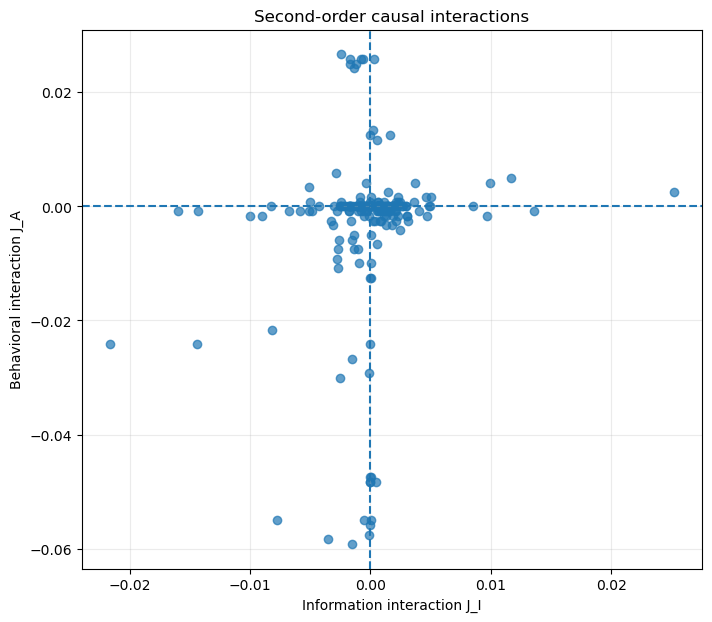

In [19]:
plt.figure(figsize=(8,7))

plt.scatter(
    pair_df["J_I"],
    pair_df["J_A"],
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Information interaction J_I"
)

plt.ylabel(
    "Behavioral interaction J_A"
)

plt.title(
    "Second-order causal interactions"
)

plt.grid(alpha=0.25)

plt.show()

In [20]:
print(
    "\nTOP BEHAVIORAL SYNERGY"
)

print(
    pair_df
    .sort_values(
        "J_A",
        ascending=False
    )
    [
        [
            "e1",
            "e2",
            "class1",
            "class2",
            "J_I",
            "J_A",
            "delta_I_pair",
            "delta_A_pair"
        ]
    ]
    .head(15)
)


TOP BEHAVIORAL SYNERGY
           e1       e2         class1            class2       J_I       J_A  \
180   (8, 11)   (4, 9)   joint-repair           neutral -0.002444  0.026667   
88    (7, 11)   (4, 9)  behavior-only           neutral  0.000294  0.025833   
72   (10, 11)   (4, 9)  behavior-only           neutral -0.000623  0.025833   
69   (10, 11)  (4, 13)  behavior-only           neutral -0.001705  0.025833   
85    (7, 11)  (4, 13)  behavior-only           neutral -0.000790  0.025833   
103  (11, 16)   (4, 9)  behavior-only           neutral -0.001186  0.025000   
100  (11, 16)  (4, 13)  behavior-only           neutral -0.001702  0.025000   
177   (8, 11)  (4, 13)   joint-repair           neutral -0.001385  0.024167   
71   (10, 11)  (5, 12)  behavior-only           neutral  0.000220  0.013333   
102  (11, 16)  (5, 12)  behavior-only           neutral  0.001653  0.012500   
179   (8, 11)  (5, 12)   joint-repair           neutral -0.000016  0.012500   
87    (7, 11)  (5, 12)  beha

In [21]:
print(
    "\nTOP INFORMATION SYNERGY"
)

print(
    pair_df
    .sort_values(
        "J_I",
        ascending=False
    )
    [
        [
            "e1",
            "e2",
            "class1",
            "class2",
            "J_I",
            "J_A",
            "delta_I_pair",
            "delta_A_pair"
        ]
    ]
    .head(15)
)


TOP INFORMATION SYNERGY
           e1        e2            class1            class2       J_I  \
124    (0, 9)    (0, 6)     behavior-only           neutral  0.025196   
111    (0, 4)    (0, 6)     behavior-only           neutral  0.013608   
205    (8, 9)    (4, 9)           neutral           neutral  0.011683   
191   (9, 19)    (8, 9)           neutral           neutral  0.009956   
105    (0, 4)    (0, 9)     behavior-only     behavior-only  0.009718   
128    (0, 9)    (8, 9)     behavior-only           neutral  0.008543   
202   (4, 13)    (4, 9)           neutral           neutral  0.004998   
68   (10, 11)  (10, 14)     behavior-only           neutral  0.004984   
142    (1, 7)    (4, 9)  information-only           neutral  0.004839   
135    (1, 7)   (8, 11)  information-only      joint-repair  0.004698   
182    (0, 6)   (9, 19)           neutral           neutral  0.004615   
6     (0, 16)    (0, 9)     behavior-only     behavior-only  0.004052   
49    (6, 16)    (0, 6)   

In [22]:
eps_I = 0.005
eps_A = 0.005

In [23]:
pure_behavior_pairs = []

pure_information_pairs = []

for _, row in pair_df.iterrows():

    e1 = ast.literal_eval(
        row["e1"]
    )

    e2 = ast.literal_eval(
        row["e2"]
    )

    A1 = single_lookup[e1][
        "delta_A"
    ]

    A2 = single_lookup[e2][
        "delta_A"
    ]

    I1 = single_lookup[e1][
        "delta_I"
    ]

    I2 = single_lookup[e2][
        "delta_I"
    ]

    if (
        abs(A1) <= eps_A
        and
        abs(A2) <= eps_A
        and
        row["delta_A_pair"] > eps_A
    ):
        pure_behavior_pairs.append(
            row.to_dict()
        )

    if (
        abs(I1) <= eps_I
        and
        abs(I2) <= eps_I
        and
        row["delta_I_pair"] > eps_I
    ):
        pure_information_pairs.append(
            row.to_dict()
        )

In [24]:
print(
    "Pure behavioral pair synergies:",
    len(pure_behavior_pairs)
)

print(
    "Pure information pair synergies:",
    len(pure_information_pairs)
)

Pure behavioral pair synergies: 0
Pure information pair synergies: 0


In [25]:
eps_I = 0.005
eps_A = 0.005

def classify_pair(row):

    dI = row["delta_I_pair"]
    dA = row["delta_A_pair"]

    JI = row["J_I"]
    JA = row["J_A"]

    # forte behavioral synergy
    if JA > eps_A and abs(JI) <= eps_I:

        if dA > eps_A:
            return "dynamical-synergy-rescue"
        else:
            return "dynamical-synergy-no-rescue"

    # forte informational synergy
    if JI > eps_I and abs(JA) <= eps_A:

        if dI > eps_I:
            return "information-synergy-rescue"
        else:
            return "information-synergy-no-rescue"

    # entrambe positive
    if JI > eps_I and JA > eps_A:

        if dI > eps_I and dA > eps_A:
            return "joint-synergy-rescue"
        else:
            return "joint-synergy-mixed"

    # ridondanza/interferenza forte
    if JI < -eps_I and JA < -eps_A:
        return "joint-antagonism"

    if JA < -eps_A and abs(JI) <= eps_I:
        return "behavioral-antagonism"

    if JI < -eps_I and abs(JA) <= eps_A:
        return "information-antagonism"

    return "weak/mixed"

In [26]:
pair_df["pair_class"] = (
    pair_df.apply(
        classify_pair,
        axis=1
    )
)

print(
    pair_df[
        "pair_class"
    ].value_counts()
)

pair_class
weak/mixed                       148
behavioral-antagonism             29
dynamical-synergy-rescue          13
information-antagonism            10
information-synergy-no-rescue      6
joint-antagonism                   4
Name: count, dtype: int64


In [27]:
print(
    pair_df[
        pair_df["pair_class"]
        == "dynamical-synergy-rescue"
    ]
    .sort_values(
        "J_A",
        ascending=False
    )
    [
        [
            "e1",
            "e2",
            "class1",
            "class2",
            "J_I",
            "J_A",
            "delta_I_pair",
            "delta_A_pair"
        ]
    ]
    .head(20)
)

           e1       e2         class1            class2       J_I       J_A  \
180   (8, 11)   (4, 9)   joint-repair           neutral -0.002444  0.026667   
72   (10, 11)   (4, 9)  behavior-only           neutral -0.000623  0.025833   
88    (7, 11)   (4, 9)  behavior-only           neutral  0.000294  0.025833   
69   (10, 11)  (4, 13)  behavior-only           neutral -0.001705  0.025833   
85    (7, 11)  (4, 13)  behavior-only           neutral -0.000790  0.025833   
103  (11, 16)   (4, 9)  behavior-only           neutral -0.001186  0.025000   
100  (11, 16)  (4, 13)  behavior-only           neutral -0.001702  0.025000   
177   (8, 11)  (4, 13)   joint-repair           neutral -0.001385  0.024167   
71   (10, 11)  (5, 12)  behavior-only           neutral  0.000220  0.013333   
102  (11, 16)  (5, 12)  behavior-only           neutral  0.001653  0.012500   
179   (8, 11)  (5, 12)   joint-repair           neutral -0.000016  0.012500   
87    (7, 11)  (5, 12)  behavior-only           neut

In [28]:
pairs_to_check = (
    pair_df[
        pair_df["pair_class"]
        == "dynamical-synergy-rescue"
    ]
    .sort_values(
        "J_A",
        ascending=False
    )
    .reset_index(drop=True)
)

print(len(pairs_to_check))
print(
    pairs_to_check[
        [
            "e1",
            "e2",
            "J_I",
            "J_A"
        ]
    ]
)

13
          e1       e2       J_I       J_A
0    (8, 11)   (4, 9) -0.002444  0.026667
1   (10, 11)   (4, 9) -0.000623  0.025833
2    (7, 11)   (4, 9)  0.000294  0.025833
3   (10, 11)  (4, 13) -0.001705  0.025833
4    (7, 11)  (4, 13) -0.000790  0.025833
5   (11, 16)   (4, 9) -0.001186  0.025000
6   (11, 16)  (4, 13) -0.001702  0.025000
7    (8, 11)  (4, 13) -0.001385  0.024167
8   (10, 11)  (5, 12)  0.000220  0.013333
9   (11, 16)  (5, 12)  0.001653  0.012500
10   (8, 11)  (5, 12) -0.000016  0.012500
11   (7, 11)  (5, 12)  0.000521  0.011667
12   (1, 16)   (1, 8) -0.002899  0.005833


In [29]:
def condition_outputs(W_use):

    trace = batch_trace_states(
        X_eval,
        W_use,
        max_sweeps=6
    )

    # -----------------------------
    # stato dopo primo sweep
    # -----------------------------

    s1 = trace[
        min(1, trace.shape[0] - 1)
    ]

    M, N = patterns.shape

    overlaps = (
        s1 @ patterns.T
    ) / N

    max_values = (
        overlaps.max(dim=1).values
    )

    winners = (
        overlaps.argmax(dim=1)
    )

    ties = (
        torch.abs(
            overlaps
            - max_values.unsqueeze(1)
        ) < 1e-12
    ).sum(dim=1) > 1

    decoded = winners.clone()

    decoded[ties] = -1

    # -----------------------------
    # stato finale
    # -----------------------------

    final_state = trace[-1]

    correct = torch.all(
        final_state
        == patterns[labels_eval],
        dim=1
    )

    return (
        decoded.cpu().numpy(),
        correct.cpu().numpy().astype(float)
    )

In [30]:
output_cache = {}

output_cache["baseline"] = (
    condition_outputs(W)
)

In [31]:
def W_with_edges_removed(
    W,
    edges
):

    W_do = W.clone()

    for i, j in edges:

        W_do[i, j] = 0.0
        W_do[j, i] = 0.0

    return W_do

In [32]:
import ast

for _, row in pairs_to_check.iterrows():

    e1 = ast.literal_eval(
        row["e1"]
    )

    e2 = ast.literal_eval(
        row["e2"]
    )

    key1 = f"single:{e1}"
    key2 = f"single:{e2}"
    key12 = f"pair:{e1}|{e2}"

    if key1 not in output_cache:

        output_cache[key1] = (
            condition_outputs(
                W_with_edges_removed(
                    W,
                    [e1]
                )
            )
        )

    if key2 not in output_cache:

        output_cache[key2] = (
            condition_outputs(
                W_with_edges_removed(
                    W,
                    [e2]
                )
            )
        )

    output_cache[key12] = (
        condition_outputs(
            W_with_edges_removed(
                W,
                [e1, e2]
            )
        )
    )

In [33]:
labels_np = (
    labels_eval
    .cpu()
    .numpy()
)

classes = np.unique(
    labels_np
)

H_M = np.log2(
    len(classes)
)

In [34]:
def metrics_from_indices(
    key,
    indices
):

    decoded, correct = (
        output_cache[key]
    )

    mi = discrete_mutual_information(
        labels_np[indices],
        decoded[indices]
    ) / H_M

    acc = correct[
        indices
    ].mean()

    return mi, acc

In [35]:
def bootstrap_pair(
    e1,
    e2,
    B=1000,
    seed=123
):

    rng = np.random.default_rng(
        seed
    )

    key1 = f"single:{e1}"
    key2 = f"single:{e2}"
    key12 = f"pair:{e1}|{e2}"

    results = []

    class_indices = {
        mu:
        np.where(
            labels_np == mu
        )[0]
        for mu in classes
    }

    for _ in range(B):

        sampled = []

        for mu in classes:

            ids = class_indices[mu]

            boot_ids = rng.choice(
                ids,
                size=len(ids),
                replace=True
            )

            sampled.append(
                boot_ids
            )

        idx = np.concatenate(
            sampled
        )

        I0, A0 = metrics_from_indices(
            "baseline",
            idx
        )

        I1, A1 = metrics_from_indices(
            key1,
            idx
        )

        I2, A2 = metrics_from_indices(
            key2,
            idx
        )

        I12, A12 = metrics_from_indices(
            key12,
            idx
        )

        JI = (
            I12
            - I1
            - I2
            + I0
        )

        JA = (
            A12
            - A1
            - A2
            + A0
        )

        results.append(
            (JI, JA)
        )

    return np.array(
        results
    )

In [36]:
bootstrap_rows = []

for k, row in pairs_to_check.iterrows():

    e1 = ast.literal_eval(
        row["e1"]
    )

    e2 = ast.literal_eval(
        row["e2"]
    )

    boot = bootstrap_pair(
        e1,
        e2,
        B=1000,
        seed=1000 + k
    )

    JI = boot[:, 0]
    JA = boot[:, 1]

    bootstrap_rows.append({
        "e1": str(e1),
        "e2": str(e2),

        "JI_median":
            np.median(JI),

        "JI_lo":
            np.percentile(
                JI, 2.5
            ),

        "JI_hi":
            np.percentile(
                JI, 97.5
            ),

        "JA_median":
            np.median(JA),

        "JA_lo":
            np.percentile(
                JA, 2.5
            ),

        "JA_hi":
            np.percentile(
                JA, 97.5
            )
    })


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

print(bootstrap_df)

          e1       e2  JI_median     JI_lo     JI_hi  JA_median     JA_lo  \
0    (8, 11)   (4, 9)  -0.002374 -0.007060  0.001156   0.026667  0.018333   
1   (10, 11)   (4, 9)  -0.000613 -0.003227  0.002084   0.025833  0.018333   
2    (7, 11)   (4, 9)   0.000567 -0.002559  0.004123   0.025833  0.017500   
3   (10, 11)  (4, 13)  -0.001459 -0.003241  0.000086   0.025833  0.017500   
4    (7, 11)  (4, 13)  -0.000507 -0.002696  0.001598   0.025833  0.018312   
5   (11, 16)   (4, 9)  -0.000825 -0.003124  0.001345   0.025000  0.016667   
6   (11, 16)  (4, 13)  -0.001448 -0.003295  0.000074   0.025000  0.017479   
7    (8, 11)  (4, 13)  -0.001214 -0.004023  0.000610   0.024167  0.015833   
8   (10, 11)  (5, 12)  -0.000172 -0.006154  0.006842   0.013333  0.007500   
9   (11, 16)  (5, 12)   0.001521 -0.004018  0.007888   0.012500  0.007500   
10   (8, 11)  (5, 12)  -0.000233 -0.005698  0.006889   0.012500  0.006667   
11   (7, 11)  (5, 12)   0.000499 -0.005351  0.007836   0.011667  0.005833   

In [37]:
from collections import Counter
import numpy as np

e1 = (8, 11)
e2 = (4, 9)

key1 = f"single:{e1}"
key2 = f"single:{e2}"
key12 = f"pair:{e1}|{e2}"

_, a0 = output_cache["baseline"]
_, a1 = output_cache[key1]
_, a2 = output_cache[key2]
_, a12 = output_cache[key12]

a0 = a0.astype(int)
a1 = a1.astype(int)
a2 = a2.astype(int)
a12 = a12.astype(int)

j_sample = (
    a12
    - a1
    - a2
    + a0
)

print(
    "J_A reconstructed:",
    j_sample.mean()
)

J_A reconstructed: 0.02666666666666667


In [38]:
configs = Counter(
    zip(a0, a1, a2, a12)
)

rows = []

for config, count in configs.items():

    b0, b1, b2, b12 = config

    j = (
        b12
        - b1
        - b2
        + b0
    )

    rows.append({
        "A0": b0,
        "A1": b1,
        "A2": b2,
        "A12": b12,
        "count": count,
        "sample_JA": j
    })

config_df = (
    pd.DataFrame(rows)
    .sort_values(
        ["sample_JA", "count"],
        ascending=[False, False]
    )
)

print(config_df)

   A0  A1  A2  A12  count  sample_JA
5   0   0   0    1     32          1
0   0   0   0    0   1024          0
1   1   1   1    1     85          0
3   0   1   0    1     51          0
2   0   0   1    1      4          0
4   1   1   0    0      4          0


In [39]:
pure_pair_mask = (
    (a0 == 0)
    &
    (a1 == 0)
    &
    (a2 == 0)
    &
    (a12 == 1)
)

print(
    "Pure pair rescued examples:",
    pure_pair_mask.sum()
)

print(
    "Fraction:",
    pure_pair_mask.mean()
)

Pure pair rescued examples: 32
Fraction: 0.02666666666666667


In [40]:
def soft_async_sweep_batch(
    states,
    W,
    beta
):

    s = states.clone()

    B, N = s.shape

    for i in range(N):

        field = (
            s * W[i].unsqueeze(0)
        ).sum(dim=1)

        new_value = torch.tanh(
            beta * field
        )

        # aggiornamento senza perdere
        # la struttura autograd
        mask = torch.zeros_like(s)
        mask[:, i] = 1.0

        s = (
            s
            +
            mask
            *
            (
                new_value
                - s[:, i]
            ).unsqueeze(1)
        )

    return s

In [41]:
def soft_retrieve_batch(
    X,
    W,
    beta,
    sweeps=6
):

    s = X.clone()

    trace = [
        s.clone()
    ]

    for _ in range(sweeps):

        s = soft_async_sweep_batch(
            s,
            W,
            beta
        )

        trace.append(
            s.clone()
        )

    return torch.stack(
        trace
    )

In [42]:
def soft_condition_metrics(
    W_use,
    beta,
    sweeps=6
):

    trace = soft_retrieve_batch(
        X_eval,
        W_use,
        beta,
        sweeps=sweeps
    )

    # decoded MI dopo primo sweep
    s1 = trace[1]

    I1 = decoded_mi(
        s1,
        labels_eval,
        patterns
    )

    final = trace[-1]

    # output discreto
    final_sign = torch.where(
        final >= 0,
        torch.ones_like(final),
        -torch.ones_like(final)
    )

    accuracy = torch.all(
        final_sign
        ==
        patterns[labels_eval],
        dim=1
    ).float().mean().item()

    # osservabile continuo
    target_overlap = (
        final
        *
        patterns[labels_eval]
    ).mean(dim=1).mean().item()

    return (
        I1,
        accuracy,
        target_overlap
    )

In [43]:
e1 = (8, 11)
e2 = (4, 9)

W1 = W_with_edges_removed(
    W,
    [e1]
)

W2 = W_with_edges_removed(
    W,
    [e2]
)

W12 = W_with_edges_removed(
    W,
    [e1, e2]
)

In [44]:
beta_values = [
    0.5,
    1.0,
    2.0,
    4.0,
    8.0,
    16.0
]

soft_rows = []

for beta in beta_values:

    I0, A0, O0 = soft_condition_metrics(
        W,
        beta
    )

    I1, A1, O1 = soft_condition_metrics(
        W1,
        beta
    )

    I2, A2, O2 = soft_condition_metrics(
        W2,
        beta
    )

    I12, A12, O12 = soft_condition_metrics(
        W12,
        beta
    )

    JI = (
        I12 - I1 - I2 + I0
    )

    JA = (
        A12 - A1 - A2 + A0
    )

    JO = (
        O12 - O1 - O2 + O0
    )

    soft_rows.append({
        "beta": beta,

        "A0": A0,
        "I0": I0,
        "O0": O0,

        "J_I": JI,
        "J_A": JA,
        "J_overlap": JO
    })


soft_df = pd.DataFrame(
    soft_rows
)

print(soft_df)

   beta        A0        I0        O0       J_I       J_A     J_overlap
0   0.5  0.000000  0.498525  0.021325  0.000177  0.000000 -9.126961e-07
1   1.0  0.000000  0.489159  0.342612  0.010474  0.000000  3.938973e-04
2   2.0  0.043333  0.474190  0.476469 -0.008633 -0.005000 -1.063854e-03
3   4.0  0.063333  0.463777  0.507835  0.001092  0.062500  3.984213e-03
4   8.0  0.070000  0.447773  0.515774 -0.005916  0.025833  2.907813e-03
5  16.0  0.072500  0.447008  0.520704 -0.003543  0.026667  4.007101e-03


In [45]:
soft_df.to_csv(
    "phase3_soft_continuation.csv",
    index=False
)

In [46]:
e1 = (8, 11)
e2 = (4, 9)

def scale_pair_edges(
    W,
    a,
    b
):
    W_scaled = W.clone()

    i, j = e1
    W_scaled[i, j] = a * W[i, j]
    W_scaled[j, i] = a * W[j, i]

    i, j = e2
    W_scaled[i, j] = b * W[i, j]
    W_scaled[j, i] = b * W[j, i]

    return W_scaled

In [47]:
X_pure = X_eval[
    torch.tensor(pure_pair_mask)
]

labels_pure = labels_eval[
    torch.tensor(pure_pair_mask)
]

In [48]:
def mean_target_overlap_soft(
    W_use,
    beta,
    sweeps=6
):
    trace = soft_retrieve_batch(
        X_pure,
        W_use,
        beta,
        sweeps=sweeps
    )

    final = trace[-1]

    targets = patterns[
        labels_pure
    ]

    overlap = (
        final * targets
    ).mean(dim=1)

    return overlap.mean().item()

In [49]:
grid = np.linspace(
    0.0,
    1.0,
    21
)

beta = 4.0

surface = np.zeros(
    (len(grid), len(grid))
)

a_zoom = np.linspace(
    0.50,
    0.75,
    51
)

b_zoom = np.linspace(
    0.32,
    0.58,
    53
)

for ia, a in enumerate(grid):

    for ib, b in enumerate(grid):

        W_ab = scale_pair_edges(
            W,
            a_zoom,
            b_zoom
        )

        surface[ia, ib] = (
            mean_target_overlap_soft(
                W_ab,
                beta
            )
        )

TypeError: unsupported operand type(s) for *: 'numpy.ndarray' and 'Tensor'

In [ ]:
a_zoom = np.linspace(
    0.50,
    0.75,
    51
)

b_zoom = np.linspace(
    0.32,
    0.58,
    53
)

beta = 4.0

surface_zoom = np.zeros(
    (
        len(a_zoom),
        len(b_zoom)
    )
)

for ia, a in enumerate(a_zoom):

    for ib, b in enumerate(b_zoom):

        W_ab = scale_pair_edges(
            W,
            a,
            b
        )

        surface_zoom[ia, ib] = (
            mean_target_overlap_soft(
                W_ab,
                beta
            )
        )

print(
    "surface min/max:",
    surface_zoom.min(),
    surface_zoom.max()
)

In [ ]:
h = grid[1] - grid[0]

mixed = np.full_like(
    surface,
    np.nan
)

for i in range(
    1,
    len(grid)-1
):

    for j in range(
        1,
        len(grid)-1
    ):

        mixed[i, j] = (
            surface[i+1, j+1]
            - surface[i+1, j-1]
            - surface[i-1, j+1]
            + surface[i-1, j-1]
        ) / (
            4 * h * h
        )

In [ ]:
plt.figure(figsize=(7,6))

plt.imshow(
    surface.T,
    origin="lower",
    extent=[0,1,0,1],
    aspect="auto"
)

plt.colorbar(
    label="Mean target overlap"
)

plt.xlabel(
    "Retention of edge (8,11)"
)

plt.ylabel(
    "Retention of edge (4,9)"
)

plt.title(
    "Soft-Hopfield response surface"
)

plt.show()

In [ ]:
da = a_zoom[1] - a_zoom[0]
db = b_zoom[1] - b_zoom[0]

mixed_zoom = np.full_like(
    surface_zoom,
    np.nan
)

for i in range(
    1,
    len(a_zoom) - 1
):

    for j in range(
        1,
        len(b_zoom) - 1
    ):

        mixed_zoom[i, j] = (
            surface_zoom[i+1, j+1]
            - surface_zoom[i+1, j-1]
            - surface_zoom[i-1, j+1]
            + surface_zoom[i-1, j-1]
        ) / (
            4 * da * db
        )

In [ ]:
plt.figure(figsize=(7, 6))

plt.imshow(
    surface_zoom.T,
    origin="lower",
    extent=[
        a_zoom[0],
        a_zoom[-1],
        b_zoom[0],
        b_zoom[-1]
    ],
    aspect="auto"
)

plt.colorbar(
    label="Mean target overlap"
)

plt.xlabel(
    "Retention of edge (8,11)"
)

plt.ylabel(
    "Retention of edge (4,9)"
)

plt.title(
    "Soft-Hopfield response surface — zoom"
)

plt.show()

In [ ]:
plt.figure(figsize=(7,6))

plt.imshow(
    mixed.T,
    origin="lower",
    extent=[0,1,0,1],
    aspect="auto"
)

plt.colorbar(
    label="Mixed curvature"
)

plt.xlabel(
    "Retention of edge (8,11)"
)

plt.ylabel(
    "Retention of edge (4,9)"
)

plt.title(
    "Where does second-order synergy arise?"
)

plt.show()

In [ ]:
plt.figure(figsize=(7, 6))

plt.imshow(
    mixed_zoom.T,
    origin="lower",
    extent=[
        a_zoom[0],
        a_zoom[-1],
        b_zoom[0],
        b_zoom[-1]
    ],
    aspect="auto"
)

plt.colorbar(
    label="Mixed curvature"
)

plt.xlabel(
    "Retention of edge (8,11)"
)

plt.ylabel(
    "Retention of edge (4,9)"
)

plt.title(
    "Mixed curvature — zoom"
)

plt.show()

In [ ]:
# Soft-Hopfield
def soft_overlap_ab(
    a,
    b,
    beta=4.0,
    sweeps=6
):
    W_ab = W.clone()

    i, j = e1
    W_ab[i, j] = a * W[i, j]
    W_ab[j, i] = a * W[j, i]

    i, j = e2
    W_ab[i, j] = b * W[i, j]
    W_ab[j, i] = b * W[j, i]

    trace = soft_retrieve_batch(
        X_pure,
        W_ab,
        beta,
        sweeps=sweeps
    )

    final = trace[-1]

    targets = patterns[
        labels_pure
    ]

    return (
        final * targets
    ).mean()

In [ ]:
a = torch.tensor(
    0.60,
    requires_grad=True
)

b = torch.tensor(
    0.40,
    requires_grad=True
)

F = soft_overlap_ab(
    a,
    b
)

dF_da = torch.autograd.grad(
    F,
    a,
    create_graph=True
)[0]

mixed_exact = torch.autograd.grad(
    dF_da,
    b
)[0]

print(
    "F =", F.item()
)

print(
    "dF/da =", dF_da.item()
)

print(
    "d2F/dadb =",
    mixed_exact.item()
)

In [ ]:
pure_ids = np.where(
    pure_pair_mask
)[0]

idx = pure_ids[0]

x_star = X_eval[idx]
mu_star = labels_eval[idx]
target_star = patterns[mu_star]

In [ ]:
def one_soft_sweep_state(
    s,
    W_use,
    beta=4.0
):
    return soft_async_sweep_batch(
        s.unsqueeze(0),
        W_use,
        beta
    )[0]

In [ ]:
pure_ids = np.where(
    pure_pair_mask
)[0]

idx = int(
    pure_ids[0]
)

x_star = (
    X_eval[idx]
    .detach()
    .clone()
)

mu_star = int(
    labels_eval[idx].item()
)

target_star = (
    patterns[mu_star]
    .detach()
    .clone()
)

print(
    "Example ID:",
    idx
)

print(
    "Target memory:",
    mu_star
)

In [ ]:
a0 = 0.60
b0 = 0.40
beta = 4.0

W_ab = scale_pair_edges(
    W,
    a0,
    b0
)

In [ ]:
trace_star = soft_retrieve_batch(
    x_star.unsqueeze(0),
    W_ab,
    beta=beta,
    sweeps=6
)

print(
    trace_star.shape
)

In [ ]:
s_star = (
    trace_star[0, 0]
    .detach()
    .clone()
    .requires_grad_(True)
)

In [ ]:
A = torch.autograd.functional.jacobian(
    lambda s:
        one_soft_sweep_state(
            s,
            W_ab,
            beta=4.0
        ),
    s_star
)

In [ ]:
eigvals = torch.linalg.eigvals(A)

singular_values = torch.linalg.svdvals(A)

rho = eigvals.abs().max()
sigma_max = singular_values.max()

In [ ]:
eigvals = torch.linalg.eigvals(
    A
)

singular_values = torch.linalg.svdvals(
    A
)

rho = (
    eigvals.abs()
    .max()
    .item()
)

sigma_max = (
    singular_values[0]
    .item()
)

print(
    "spectral radius rho =",
    rho
)

print(
    "sigma_max =",
    sigma_max
)

print(
    "\nEigenvalues:"
)

for z in eigvals:

    print(
        f"{z.real.item():+.6f}"
        f"{z.imag.item():+.6f}j"
        f" | abs={abs(z).item():.6f}"
    )

In [ ]:
spectral_rows = []

for t in range(
    trace_star.shape[0] - 1
):

    s_t = (
        trace_star[t, 0]
        .detach()
        .clone()
        .requires_grad_(True)
    )

    A_t = (
        torch.autograd.functional.jacobian(
            lambda s:
                one_soft_sweep_state(
                    s,
                    W_ab,
                    beta=beta
                ),
            s_t
        )
    )

    eig = torch.linalg.eigvals(
        A_t
    )

    sv = torch.linalg.svdvals(
        A_t
    )

    spectral_rows.append({
        "t": t,

        "rho":
            eig.abs()
            .max()
            .item(),

        "sigma_max":
            sv[0]
            .item(),

        "sigma_min":
            sv[-1]
            .item()
    })

spectral_df = pd.DataFrame(
    spectral_rows
)

print(spectral_df)

In [ ]:
E1 = torch.zeros_like(W)
E2 = torch.zeros_like(W)

i, j = e1
E1[i, j] = W[i, j]
E1[j, i] = W[j, i]

i, j = e2
E2[i, j] = W[i, j]
E2[j, i] = W[j, i]

In [ ]:
# Matrice continua
def W_from_ab(a, b):

    return (
        W
        + (a - 1.0) * E1
        + (b - 1.0) * E2
    )

In [ ]:
# Matrice osservabile
def F_ab(a, b):

    W_use = W_from_ab(
        a,
        b
    )

    trace = soft_retrieve_batch(
        X_pure,
        W_use,
        beta=4.0,
        sweeps=6
    )

    final = trace[-1]

    targets = patterns[
        labels_pure
    ]

    return (
        final * targets
    ).mean()

In [ ]:
test_points = [
    (0.60, 0.40),
    (0.60, 0.50),
    (0.70, 0.90)
]

for av, bv in test_points:

    a = torch.tensor(
        av,
        dtype=W.dtype,
        requires_grad=True
    )

    b = torch.tensor(
        bv,
        dtype=W.dtype,
        requires_grad=True
    )

    F = F_ab(
        a,
        b
    )

    dF_da = torch.autograd.grad(
        F,
        a,
        create_graph=True
    )[0]

    d2F_dadb = torch.autograd.grad(
        dF_da,
        b
    )[0]

    print(
        f"(a,b)=({av:.2f},{bv:.2f}) "
        f"| F={F.item():+.6f} "
        f"| dF/da={dF_da.item():+.6f} "
        f"| d2F/dadb={d2F_dadb.item():+.6f}"
    )

In [ ]:
conditions = {
    "baseline": (1.0, 1.0),
    "remove_e1": (0.0, 1.0),
    "remove_e2": (1.0, 0.0),
    "remove_both": (0.0, 0.0),
    "critical": (0.6, 0.4)
}

spectral_all = []

for name, (a_val, b_val) in conditions.items():

    W_cond = W_from_ab(
        torch.tensor(a_val),
        torch.tensor(b_val)
    ).detach()

    trace = soft_retrieve_batch(
        x_star.unsqueeze(0),
        W_cond,
        beta=4.0,
        sweeps=6
    )

    for t in range(trace.shape[0] - 1):

        s_t = (
            trace[t, 0]
            .detach()
            .clone()
            .requires_grad_(True)
        )

        A_t = torch.autograd.functional.jacobian(
            lambda s:
                one_soft_sweep_state(
                    s,
                    W_cond,
                    beta=4.0
                ),
            s_t
        )

        eig = torch.linalg.eigvals(A_t)
        sv = torch.linalg.svdvals(A_t)

        spectral_all.append({
            "condition": name,
            "t": t,
            "rho": eig.abs().max().item(),
            "sigma_max": sv[0].item(),
            "dominant_real":
                eig[
                    eig.abs().argmax()
                ].real.item(),
            "dominant_imag":
                eig[
                    eig.abs().argmax()
                ].imag.item()
        })

spectral_compare = pd.DataFrame(
    spectral_all
)

print(spectral_compare)

In [ ]:
plt.figure(figsize=(9,5))

for name in spectral_compare["condition"].unique():

    d = spectral_compare[
        spectral_compare["condition"]
        == name
    ]

    plt.plot(
        d["t"],
        d["rho"],
        marker="o",
        label=name
    )

plt.axhline(
    1.0,
    linestyle="--"
)

plt.xlabel("Sweep")
plt.ylabel("Spectral radius")
plt.title("Local stability across causal interventions")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [ ]:
plt.figure(figsize=(9,5))

for name in spectral_compare["condition"].unique():

    d = spectral_compare[
        spectral_compare["condition"]
        == name
    ]

    plt.plot(
        d["t"],
        d["sigma_max"],
        marker="o",
        label=name
    )

plt.axhline(
    1.0,
    linestyle="--"
)

plt.xlabel("Sweep")
plt.ylabel("Maximum singular value")
plt.title("Transient amplification across interventions")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [ ]:
def trace_microsteps(
    x,
    W_use,
    beta=4.0
):

    s = x.clone()

    rows = []

    N = len(s)

    for i in range(N):

        field = torch.dot(
            W_use[i],
            s
        ).item()

        target_margin = (
            target_star[i].item()
            * field
        )

        old = s[i].item()

        new = torch.tanh(
            torch.tensor(
                beta * field
            )
        ).item()

        rows.append({
            "neuron": i,
            "field": field,
            "target_margin":
                target_margin,
            "old_state": old,
            "new_state": new
        })

        s[i] = new

    return pd.DataFrame(rows)

In [ ]:
micro_rows = []

for name, (a_val, b_val) in {
    "baseline": (1,1),
    "remove_e1": (0,1),
    "remove_e2": (1,0),
    "remove_both": (0,0)
}.items():

    W_cond = W_from_ab(
        torch.tensor(float(a_val)),
        torch.tensor(float(b_val))
    ).detach()

    d = trace_microsteps(
        x_star,
        W_cond,
        beta=4.0
    )

    d["condition"] = name

    micro_rows.append(d)

micro_df = pd.concat(
    micro_rows,
    ignore_index=True
)

In [ ]:
margin_table = micro_df.pivot(
    index="neuron",
    columns="condition",
    values="target_margin"
)

print(margin_table)

In [ ]:
conditions_W = {
    "baseline": W_from_ab(
        torch.tensor(1.0),
        torch.tensor(1.0)
    ).detach(),

    "e1": W_from_ab(
        torch.tensor(0.0),
        torch.tensor(1.0)
    ).detach(),

    "e2": W_from_ab(
        torch.tensor(1.0),
        torch.tensor(0.0)
    ).detach(),

    "both": W_from_ab(
        torch.tensor(0.0),
        torch.tensor(0.0)
    ).detach()
}

traces = {}

for name, Wc in conditions_W.items():

    traces[name] = soft_retrieve_batch(
        x_star.unsqueeze(0),
        Wc,
        beta=4.0,
        sweeps=6
    )[:, 0, :]

In [ ]:
J_h = (
    traces["both"]
    - traces["e1"]
    - traces["e2"]
    + traces["baseline"]
)

In [ ]:
Jh_norm = torch.linalg.vector_norm(
    J_h,
    dim=1
)

for t, value in enumerate(Jh_norm):

    print(
        f"t={t} | ||J_h|| = "
        f"{value.item():.6f}"
    )

In [ ]:
Jh_abs = J_h.abs()

for t in range(
    1,
    J_h.shape[0]
):

    vals, ids = torch.topk(
        Jh_abs[t],
        k=5
    )

    print(
        f"\nt = {t}"
    )

    for idx_n, val in zip(
        ids.tolist(),
        vals.tolist()
    ):

        print(
            f"neuron {idx_n:2d} "
            f"| Jh={J_h[t, idx_n].item():+.6f} "
            f"| abs={val:.6f}"
        )

In [ ]:
for t in range(
    1,
    J_h.shape[0]
):

    repair_direction = (
        target_star
        - traces["baseline"][t]
    )

    j = J_h[t]

    denom = (
        torch.linalg.vector_norm(j)
        *
        torch.linalg.vector_norm(
            repair_direction
        )
    )

    if denom.item() > 1e-12:

        cos = torch.dot(
            j,
            repair_direction
        ) / denom

        print(
            f"t={t} | "
            f"cos(Jh, repair) = "
            f"{cos.item():+.6f}"
        )

In [ ]:
J_target_projection = (
    J_h * target_star
).mean(dim=1)

for t, val in enumerate(
    J_target_projection
):

    print(
        f"t={t} | "
        f"target projection = "
        f"{val.item():+.6f}"
    )

In [ ]:
def jacobian_at_state(
    state,
    W_use,
    beta=4.0
):

    s = (
        state.detach()
        .clone()
        .requires_grad_(True)
    )

    return (
        torch.autograd.functional.jacobian(
            lambda x:
                one_soft_sweep_state(
                    x,
                    W_use,
                    beta=beta
                ),
            s
        )
    )

In [ ]:
t = 1

A_both = jacobian_at_state(
    traces["both"][t],
    conditions_W["both"],
    beta=4.0
)

U, S, Vh = torch.linalg.svd(
    A_both
)

v1 = Vh[0]
u1 = U[:, 0]

repair_in = (
    target_star
    - traces["both"][t]
)

repair_out = (
    target_star
    - traces["both"][t+1]
)

In [ ]:
cos_v = torch.dot(
    v1,
    repair_in
) / (
    torch.linalg.vector_norm(v1)
    *
    torch.linalg.vector_norm(
        repair_in
    )
)

cos_u = torch.dot(
    u1,
    repair_out
) / (
    torch.linalg.vector_norm(u1)
    *
    torch.linalg.vector_norm(
        repair_out
    )
)

print(
    "cos(v1, repair input) =",
    cos_v.item()
)

print(
    "cos(u1, repair output) =",
    cos_u.item()
)

In [ ]:
def microstep_interaction_trace(
    x,
    W0,
    W1,
    W2,
    W12,
    beta=4.0
):

    states = {
        "base": x.clone(),
        "e1": x.clone(),
        "e2": x.clone(),
        "both": x.clone()
    }

    Ws = {
        "base": W0,
        "e1": W1,
        "e2": W2,
        "both": W12
    }

    rows = []

    N = len(x)

    for i in range(N):

        for name in states:

            s = states[name]
            Wc = Ws[name]

            field = torch.dot(
                Wc[i],
                s
            )

            s[i] = torch.tanh(
                beta * field
            )

        Jh = (
            states["both"]
            - states["e1"]
            - states["e2"]
            + states["base"]
        )

        rows.append({
            "after_neuron": i,
            "Jh_norm":
                torch.linalg.vector_norm(
                    Jh
                ).item(),

            "Jh_4":
                Jh[4].item(),

            "Jh_8":
                Jh[8].item(),

            "Jh_9":
                Jh[9].item(),

            "Jh_11":
                Jh[11].item()
        })

    return pd.DataFrame(rows)

In [ ]:
micro_J = microstep_interaction_trace(
    x_star,
    conditions_W["baseline"],
    conditions_W["e1"],
    conditions_W["e2"],
    conditions_W["both"],
    beta=4.0
)

print(micro_J)